In [20]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [21]:
# --------------------------------------------------
# STEP 1: LOAD THE DATASET
# --------------------------------------------------

# Load MNIST CSV dataset
train_data = pd.read_csv('mnist_train.csv')
test_data = pd.read_csv('mnist_test.csv')

In [22]:


x_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

x_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

In [23]:
# --------------------------------------------------
# STEP 2: PREPROCESS THE DATA
# --------------------------------------------------

# Normalize pixel values between 0 and 1
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten images into 1D vectors
x_train = x_train.reshape(x_train.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0], -1)

In [24]:
# --------------------------------------------------
# STEP 3: DEFINE THE FNN MODEL
# --------------------------------------------------

model = keras.Sequential([
    layers.Input(shape=(x_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [25]:
# --------------------------------------------------
# STEP 4: COMPILE THE MODEL
# --------------------------------------------------

model.compile(
    optimizer=keras.optimizers.SGD(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [26]:
# --------------------------------------------------
# STEP 5: TRAIN THE MODEL
# --------------------------------------------------

history = model.fit(
    x_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8214 - loss: 0.6866 - val_accuracy: 0.9227 - val_loss: 0.2892
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9101 - loss: 0.3153 - val_accuracy: 0.9402 - val_loss: 0.2229
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9261 - loss: 0.2597 - val_accuracy: 0.9447 - val_loss: 0.1999
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9364 - loss: 0.2239 - val_accuracy: 0.9563 - val_loss: 0.1667
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9435 - loss: 0.1969 - val_accuracy: 0.9600 - val_loss: 0.1513
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9492 - loss: 0.1757 - val_accuracy: 0.9623 - val_loss: 0.1387
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9541 - loss: 0.1591 - val_accuracy: 0.9647 - val_loss: 0.1312
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9580 - loss: 

In [27]:
# --------------------------------------------------
# STEP 6: EVALUATE THE MODEL
# --------------------------------------------------

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9622 - loss: 0.1203
Test Loss: 0.12032513320446014
Test Accuracy: 96.21999859809875 %


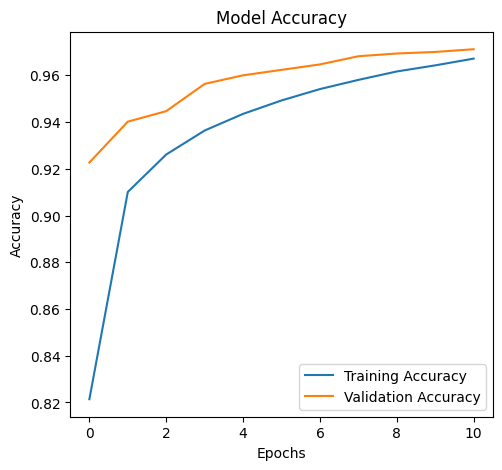

In [28]:
# --------------------------------------------------
# STEP 7: PLOT TRAINING LOSS AND ACCURACY
# --------------------------------------------------

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

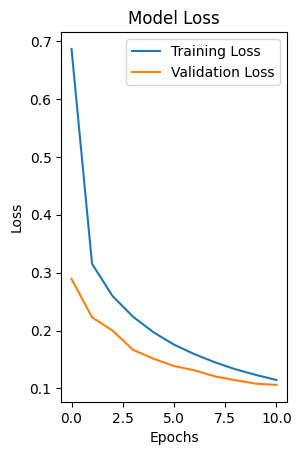

In [29]:
# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()